# 31. Convolutional NNs I: Image Operations and Convolution

Shengli (Bruce) Jiang, University of South Carolina

## Python Packages

```python
%pip install numpy matplotlib scipy scikit-image
```

**scikit-image** provides sample images and basic image tools. **SciPy** provides the convolution functions.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

In [2]:
NAVY = '#17233F'
RED = '#8E0B19'
PALE_BLUE = '#DCE4F1'
np.set_printoptions(precision=3, suppress=True)
plt.style.use('default')
plt.rcParams.update({
    'font.size': 11,
    'text.color': 'black',
    'axes.titlecolor': 'black',
    'axes.labelcolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'legend.labelcolor': 'black',
    'figure.dpi': 120,
})

## Images as Arrays

A digital image is an array of numbers. Each entry is a **pixel**, located by its row and column. Rows increase downward and columns increase rightward.

`skimage.data` contains sample images. The function `astronaut()` returns a color photograph.

In [3]:
from skimage import data

img = data.astronaut()
print('Shape:', img.shape)
print('Data type:', img.dtype)
print('Min and max:', img.min(), img.max())

Shape: (512, 512, 3)
Data type: uint8
Min and max: 0 255


The shape is (height, width, channels). The type `uint8` stores integers from 0 to 255.

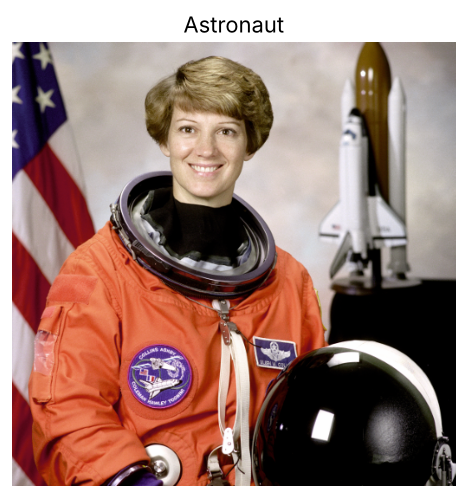

In [4]:
plt.imshow(img)
plt.title('Astronaut')
plt.axis('off')
plt.show()

Indexing with `[row, col]` returns the three color values of one pixel.

In [5]:
img[300, 100]

array([232, 129,  84], dtype=uint8)

Slicing returns a region. A 16 x 16 region around the eye shows the individual pixels.

In [6]:
eye = img[95:111, 200:216]
eye.shape

(16, 16, 3)

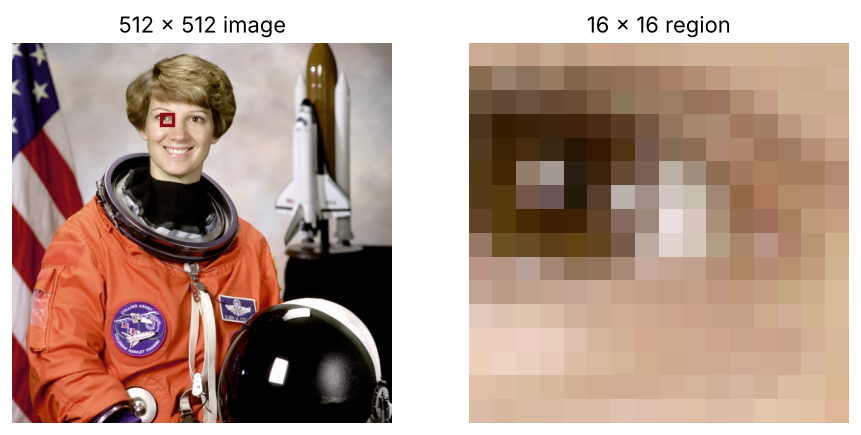

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(img)
# Rectangle takes (x, y) = (column, row)
axes[0].add_patch(plt.Rectangle((200, 95), 16, 16, fill=False, edgecolor=RED, linewidth=2))
axes[0].set_title('512 x 512 image')
axes[1].imshow(eye)
axes[1].set_title('16 x 16 region')
for ax in axes:
    ax.axis('off')
plt.show()

## RGB Channels

A color image stores three measurements at each pixel, one each for red, green, and blue. Each **channel** is a 2D array with the same height and width.

In [8]:
R = img[:, :, 0]
G = img[:, :, 1]
B = img[:, :, 2]
print(R.shape, G.shape, B.shape)

(512, 512) (512, 512) (512, 512)


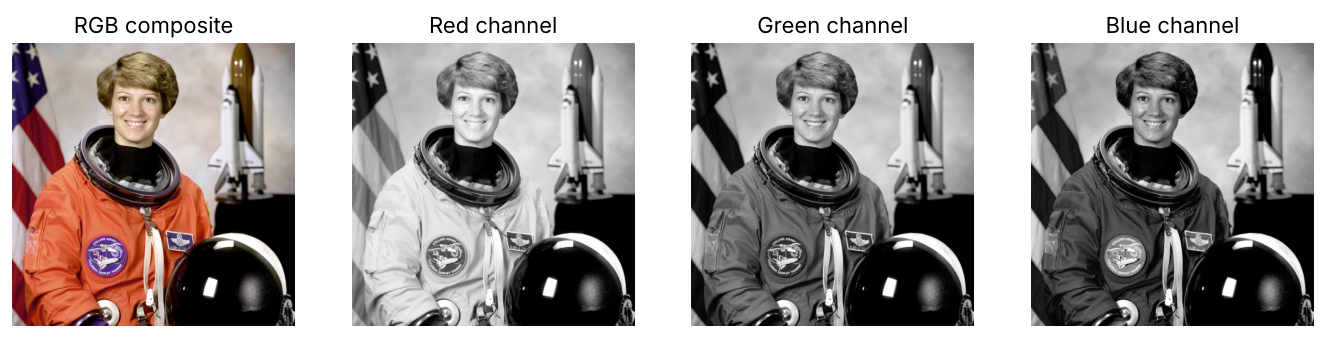

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
axes[0].imshow(img)
axes[0].set_title('RGB composite')
for ax, channel, name in zip(axes[1:], [R, G, B], ['Red', 'Green', 'Blue']):
    ax.imshow(channel, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'{name} channel')
for ax in axes:
    ax.axis('off')
plt.show()

Bright pixels have large values in that channel. The orange suit is bright in the red channel and dark in the blue channel.

## Images Are Tensors

A **tensor** is a multidimensional array. Its axes identify what each index selects. Keras uses **channels last**, so an image has shape (height, width, channels).

In [10]:
print('H x W:', R.shape)

H x W: (512, 512)


`np.newaxis` adds an axis of length 1. Keras layers expect a channel axis even for a single-channel image.

In [11]:
R_channel = R[:, :, np.newaxis]
print('H x W x 1:', R_channel.shape)

H x W x 1: (512, 512, 1)


In [12]:
print('H x W x 3:', img.shape)

H x W x 3: (512, 512, 3)


`np.stack` places several images along a new first axis, the **batch** axis.

In [13]:
batch = np.stack([img, img, img, img])
print('B x H x W x 3:', batch.shape)

B x H x W x 3: (4, 512, 512, 3)


## Grayscale

A grayscale image has one intensity value per pixel. OpenCV uses the weighted sum

$$Y = 0.299R + 0.587G + 0.114B.$$

The weights sum to 1, so a white pixel stays at 255.

In [14]:
weights = np.array([0.299, 0.587, 0.114])
pixel = img[300, 100]
print('RGB:', pixel)
print(f'Gray: {pixel @ weights:.1f}')

RGB: [232 129  84]
Gray: 154.7


The `@` operator computes the weighted sum. Applied to the whole image, it combines the channel axis and leaves one value per pixel.

In [15]:
gray = img @ weights
gray.shape

(512, 512)

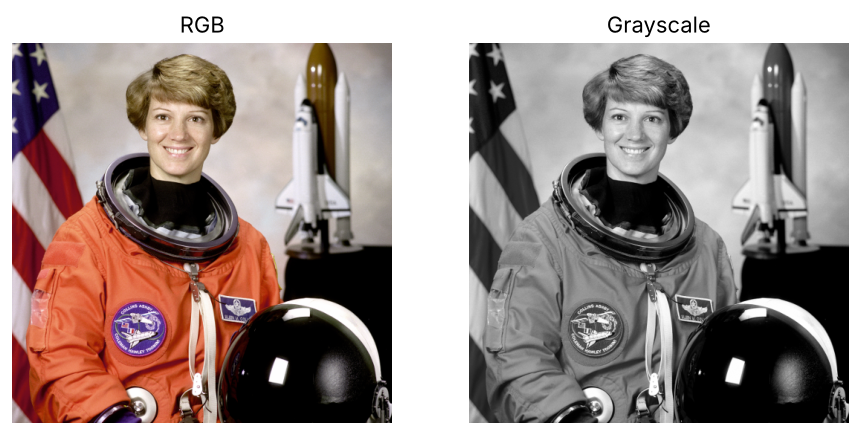

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(img)
axes[0].set_title('RGB')
axes[1].imshow(gray, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Grayscale')
for ax in axes:
    ax.axis('off')
plt.show()

Different colors can give nearly the same gray value. An orange pixel and a neutral gray pixel are almost indistinguishable after conversion, so color cannot be recovered from grayscale.

In [17]:
print(f'Orange: {np.array([232, 129, 84]) @ weights:.1f}')
print(f'Gray:   {np.array([155, 155, 155]) @ weights:.1f}')

Orange: 154.7
Gray:   155.0


The remaining sections scale intensities to the range [0, 1].

In [18]:
gray = gray / 255
print(gray.min(), gray.max())

0.0 1.0


## Point Operations

A **point operation** computes each output pixel from the same input pixel alone.

- **Brightness** adds a constant.
- **Contrast** stretches values away from 0.5.
- A **power transform** with exponent 0.5 brightens dark pixels more than bright ones.

`np.clip` keeps the results in [0, 1].

In [19]:
bright = np.clip(gray + 0.2, 0, 1)
contrast = np.clip(0.5 + 1.6 * (gray - 0.5), 0, 1)
power = gray ** 0.5

The function `show_row` displays several grayscale images side by side.

In [20]:
def show_row(images, titles, vmin=0, vmax=1):
    fig, axes = plt.subplots(1, len(images), figsize=(3.6 * len(images), 3.8))
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image, cmap='gray', vmin=vmin, vmax=vmax)
        ax.set_title(title)
        ax.axis('off')
    plt.show()

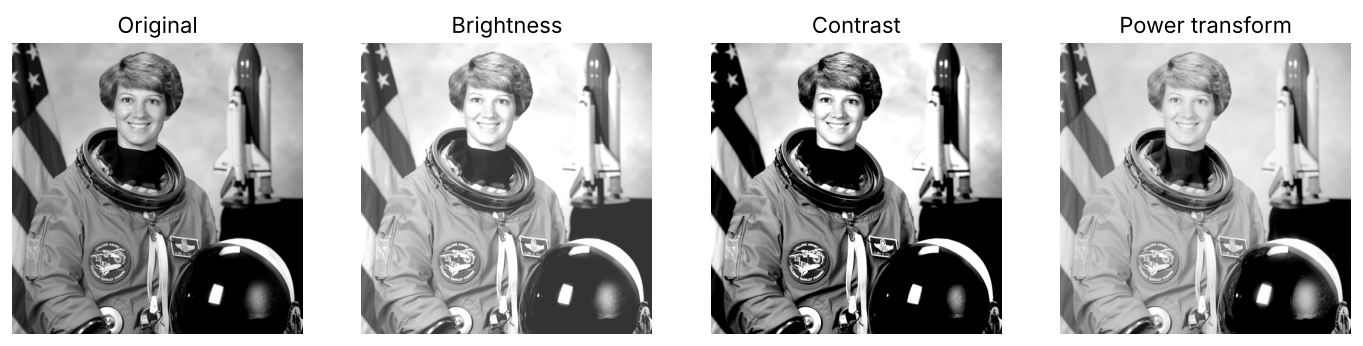

In [21]:
show_row(
    [gray, bright, contrast, power],
    ['Original', 'Brightness', 'Contrast', 'Power transform'],
)

Each point operation is a function from input value to output value.

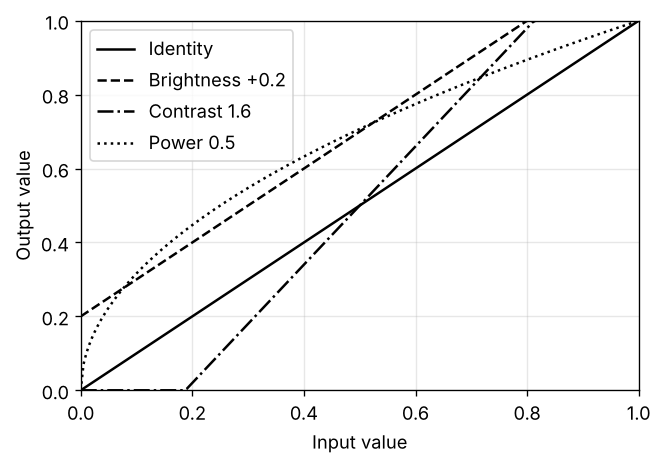

In [22]:
x = np.linspace(0, 1, 201)

plt.figure(figsize=(6, 4))
plt.plot(x, x, 'k-', label='Identity')
plt.plot(x, np.clip(x + 0.2, 0, 1), 'k--', label='Brightness +0.2')
plt.plot(x, np.clip(0.5 + 1.6 * (x - 0.5), 0, 1), 'k-.', label='Contrast 1.6')
plt.plot(x, x ** 0.5, 'k:', label='Power 0.5')
plt.xlabel('Input value')
plt.ylabel('Output value')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [23]:
x0 = 0.25
print(f'Brightness: {np.clip(x0 + 0.2, 0, 1):.2f}')
print(f'Contrast:   {np.clip(0.5 + 1.6 * (x0 - 0.5), 0, 1):.2f}')
print(f'Power:      {x0 ** 0.5:.2f}')

Brightness: 0.45
Contrast:   0.10
Power:      0.50


## Resizing

Resizing places a new sampling grid on the image. **Interpolation** defines how the new grid obtains its values.

`skimage.transform.resize` takes the output shape and an interpolation `order`. Order 0 is nearest neighbor, and order 1 is bilinear.

In [24]:
from skimage.transform import resize

face = img[40:200, 150:310]
small = resize(face, (16, 16), anti_aliasing=True)
print(face.shape, small.shape)

(160, 160, 3) (16, 16, 3)


In [25]:
nearest = resize(small, (160, 160), order=0)
bilinear = resize(small, (160, 160), order=1)

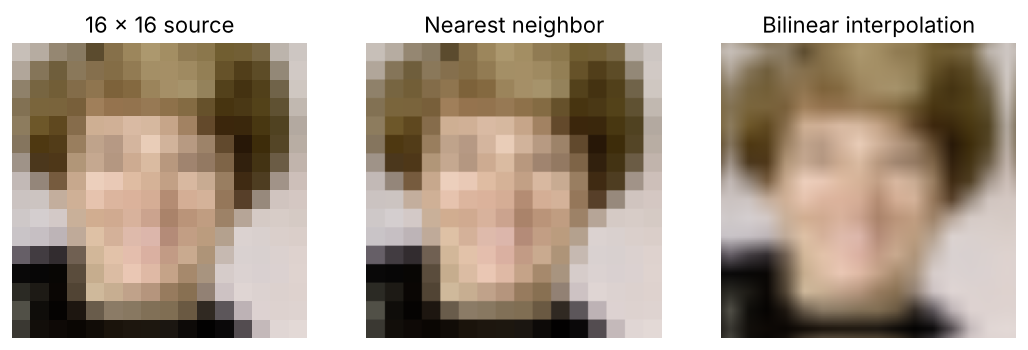

In [26]:
show_row(
    [small, nearest, bilinear],
    ['16 x 16 source', 'Nearest neighbor', 'Bilinear interpolation'],
)

Linear interpolation between values $a$ and $b$ at fraction $t$ is

$$y = (1 - t)a + tb.$$

Halfway between 20 and 100, it gives 60.

In [27]:
np.interp(0.5, [0, 1], [20, 100])

np.float64(60.0)

Bilinear interpolation looks smoother, but it cannot restore detail lost in the 16 x 16 image.

## Neighborhood Operations

A **neighborhood operation** computes each output pixel from a patch of surrounding pixels. A spatial **filter** applies the same rule at every location.

In [28]:
patch = np.array([
    [20, 20, 80],
    [20, 20, 80],
    [20, 20, 80],
])

In [29]:
print('Identity:', patch[1, 1])
print('3 x 3 average:', patch.mean())
print('Median:', np.median(patch))

Identity: 20
3 x 3 average: 40.0
Median: 20.0


The average is a weighted sum with every weight equal to 1/9, so it is a convolution. The median sorts the values instead, so it is a different kind of neighborhood operation.

## Convolution of One Patch

Convolution multiplies a patch by a **kernel** elementwise and sums the products. The result is one output value.

The kernel below responds to a change from left to right.

In [30]:
patch = np.array([
    [10, 10, 50],
    [10, 10, 50],
    [10, 10, 50],
])

kernel = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1],
])

In [31]:
patch * kernel

array([[-10,   0,  50],
       [-20,   0, 100],
       [-10,   0,  50]])

In [32]:
np.sum(patch * kernel)

np.int64(160)

## Sliding the Kernel

Convolution reuses the same kernel at every location. A 3 x 3 kernel fits at 3 x 3 positions inside a 5 x 5 input, so the output is 3 x 3.

In [33]:
X = np.array([
    [10, 10, 10, 50, 50],
    [10, 10, 10, 50, 50],
    [10, 10, 10, 50, 50],
    [10, 10, 10, 50, 50],
    [10, 10, 10, 50, 50],
])

The patch in the top-left corner is uniform, so the output is 0.

In [34]:
np.sum(X[0:3, 0:3] * kernel)

np.int64(0)

Shifting the window one column to the right brings the change from 10 to 50 inside the patch.

In [35]:
np.sum(X[0:3, 1:4] * kernel)

np.int64(160)

A loop visits every valid position.

In [36]:
out = np.zeros((3, 3))
for i in range(3):
    for j in range(3):
        out[i, j] = np.sum(X[i:i+3, j:j+3] * kernel)
out

array([[  0., 160., 160.],
       [  0., 160., 160.],
       [  0., 160., 160.]])

`scipy.signal.correlate2d` gives the same result. The option `mode='valid'` keeps only positions where the kernel fits entirely inside the input.

In [37]:
from scipy.signal import correlate2d

correlate2d(X, kernel, mode='valid')

array([[  0, 160, 160],
       [  0, 160, 160],
       [  0, 160, 160]])

Strictly, mathematical convolution flips the kernel before sliding it. The operation above, without the flip, is called **cross-correlation**. Deep learning libraries, including Keras, compute cross-correlation and call it convolution.

`scipy.signal.convolve2d` flips the kernel, which reverses the sign here.

In [38]:
from scipy.signal import convolve2d

convolve2d(X, kernel, mode='valid')

array([[   0, -160, -160],
       [   0, -160, -160],
       [   0, -160, -160]])

For a full image, `scipy.ndimage.correlate` returns an output with the same shape as the input. Near the border, it fills the missing neighbors by reflecting the image.

## Box Blur

A **box blur** averages all pixels in the window equally. A k x k box kernel has every weight equal to 1/k², so the weights sum to 1 and the average brightness is preserved.

In [39]:
box3 = np.ones((3, 3)) / 9
print(box3)
print('Sum:', box3.sum())

[[0.111 0.111 0.111]
 [0.111 0.111 0.111]
 [0.111 0.111 0.111]]
Sum: 1.0


In [40]:
from scipy.ndimage import correlate

blur3 = correlate(gray, box3)
blur15 = correlate(gray, np.ones((15, 15)) / 225)

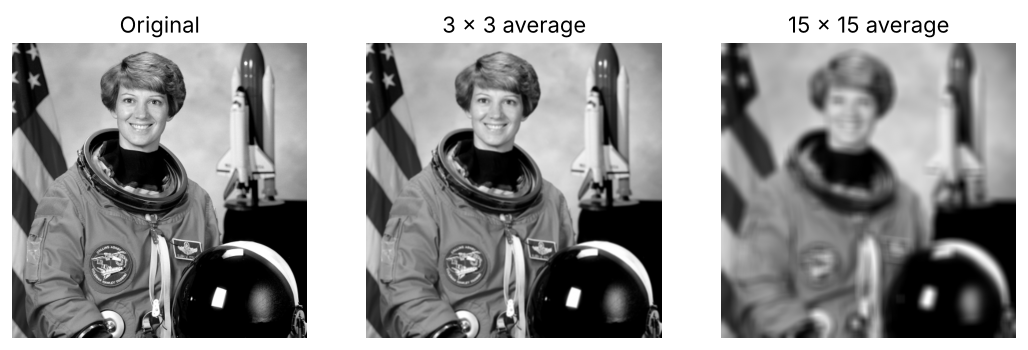

In [41]:
show_row(
    [gray, blur3, blur15],
    ['Original', '3 x 3 average', '15 x 15 average'],
)

A larger window averages over more pixels and blurs more.

## Gaussian Blur

A **Gaussian blur** weights nearby pixels more than distant ones,

$$K[u,v] \propto \exp\left(-\frac{u^2+v^2}{2\sigma^2}\right),$$

where $(u, v)$ is the offset from the center of the kernel.

The binomial weights [1, 2, 1] approximate a 1D Gaussian. `np.outer` builds the 3 x 3 kernel from them.

In [42]:
g1 = np.array([1, 2, 1])
gauss3 = np.outer(g1, g1) / 16
print(gauss3 * 16)
print('Sum:', gauss3.sum())

[[1. 2. 1.]
 [2. 4. 2.]
 [1. 2. 1.]]
Sum: 1.0


An 11 x 11 kernel with $\sigma = 2$ follows directly from the formula. Dividing by the sum makes the weights sum to 1.

In [43]:
sigma = 2
u = np.arange(-5, 6)
U, V = np.meshgrid(u, u)

gauss11 = np.exp(-(U**2 + V**2) / (2 * sigma**2))
gauss11 = gauss11 / gauss11.sum()
gauss11.shape

(11, 11)

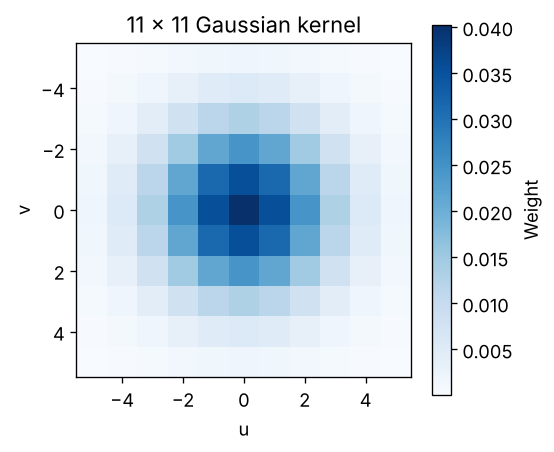

In [44]:
plt.figure(figsize=(4.5, 4))
plt.imshow(gauss11, cmap='Blues', extent=[-5.5, 5.5, 5.5, -5.5])
plt.colorbar(label='Weight')
plt.xlabel('u')
plt.ylabel('v')
plt.title('11 x 11 Gaussian kernel')
plt.show()

In [45]:
smooth3 = correlate(gray, gauss3)
smooth11 = correlate(gray, gauss11)

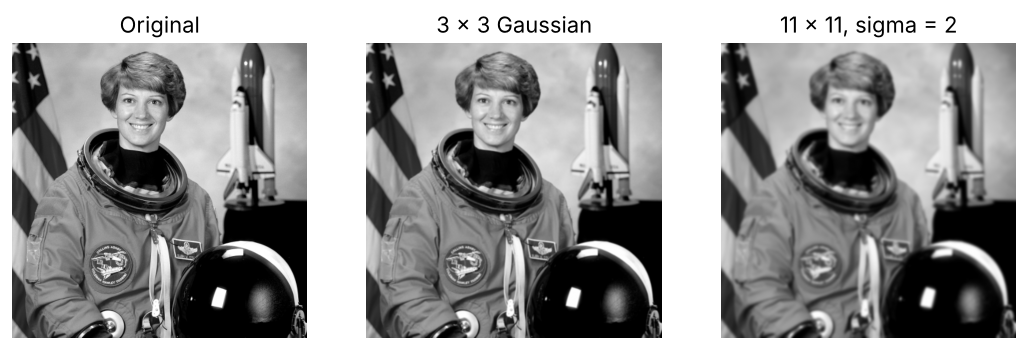

In [46]:
show_row(
    [gray, smooth3, smooth11],
    ['Original', '3 x 3 Gaussian', '11 x 11, sigma = 2'],
)

`scipy.ndimage.gaussian_filter` builds and applies the kernel in one call. With `truncate=2.5`, the kernel extends 5 pixels from the center, which is the same 11 x 11 window.

In [47]:
from scipy.ndimage import gaussian_filter

smooth_fast = gaussian_filter(gray, sigma=2, truncate=2.5)
np.allclose(smooth_fast, smooth11)

True

## Noise Reduction

Averaging also reduces random noise, because independent fluctuations partly cancel. The function `chelsea()` returns a photograph of a cat.

In [48]:
cat = data.chelsea() @ weights / 255

rng = np.random.default_rng(31)
noisy = np.clip(cat + rng.normal(0, 0.1, cat.shape), 0, 1)

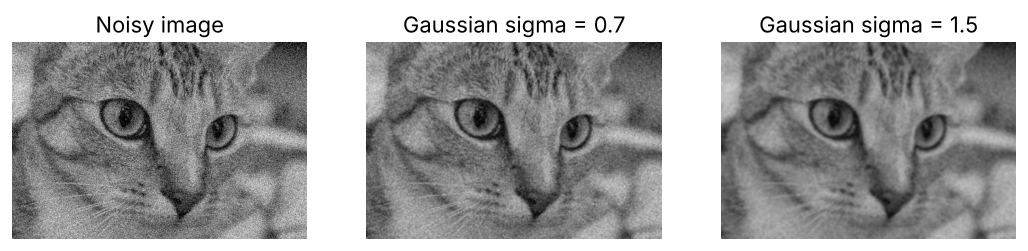

In [49]:
show_row(
    [noisy, gaussian_filter(noisy, 0.7), gaussian_filter(noisy, 1.5)],
    ['Noisy image', 'Gaussian sigma = 0.7', 'Gaussian sigma = 1.5'],
)

A larger $\sigma$ removes more noise but also blurs fine detail such as the whiskers.

## Edges as Intensity Changes

An **edge** is a rapid change in intensity. The forward difference

$$\Delta_x I = I[i, j+1] - I[i, j]$$

is zero in a uniform region and large at a step.

In [50]:
row = np.array([20, 20, 20, 80, 80])
np.diff(row)

array([ 0,  0, 60,  0])

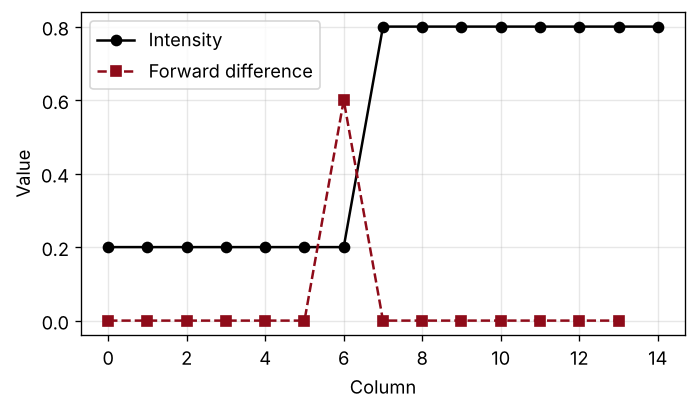

In [51]:
profile = np.where(np.arange(15) < 7, 0.2, 0.8)
forward = np.diff(profile)

plt.figure(figsize=(6.5, 3.5))
plt.plot(np.arange(15), profile, 'ko-', label='Intensity')
plt.plot(np.arange(14), forward, 's--', color=RED, label='Forward difference')
plt.xlabel('Column')
plt.ylabel('Value')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

The forward difference is a convolution with the kernel [-1, 1]. Edge kernels for images extend this idea to two dimensions.

## Sobel Filters

**Sobel x** combines a central difference across columns, [-1, 0, 1], with smoothing down rows, [1, 2, 1]. The smoothing reduces sensitivity to noise. **Sobel y** is its transpose and responds to change from top to bottom.

In [52]:
sobel_x = np.outer([1, 2, 1], [-1, 0, 1])
sobel_x

array([[-1,  0,  1],
       [-2,  0,  2],
       [-1,  0,  1]])

In [53]:
sobel_y = sobel_x.T
sobel_y

array([[-1, -2, -1],
       [ 0,  0,  0],
       [ 1,  2,  1]])

In [54]:
gx = correlate(gray, sobel_x)
gy = correlate(gray, sobel_y)

Edge responses are positive or negative. The function `show_signed` scales each response symmetrically about zero, so zero appears as middle gray.

In [55]:
def show_signed(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(3.6 * len(images), 3.8))
    for ax, image, title in zip(axes, images, titles):
        lim = np.percentile(np.abs(image), 99)
        ax.imshow(image, cmap='gray', vmin=-lim, vmax=lim)
        ax.set_title(title)
        ax.axis('off')
    plt.show()

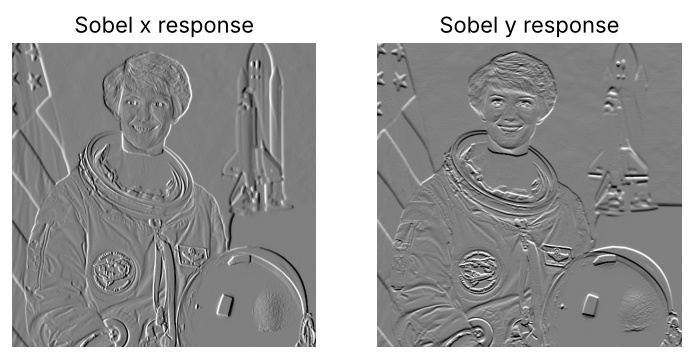

In [56]:
show_signed([gx, gy], ['Sobel x response', 'Sobel y response'])

Sobel x highlights vertical edges, such as the sides of the rocket. Sobel y highlights horizontal edges, such as the mouth.

The **gradient magnitude** combines both directions into one edge strength.

In [57]:
magnitude = np.hypot(gx, gy)

`skimage.feature.canny` smooths the image, computes gradients, and keeps only thin, connected lines of strong gradient. The result is a binary **edge map**.

In [58]:
from skimage.feature import canny

edges = canny(gray, sigma=2)

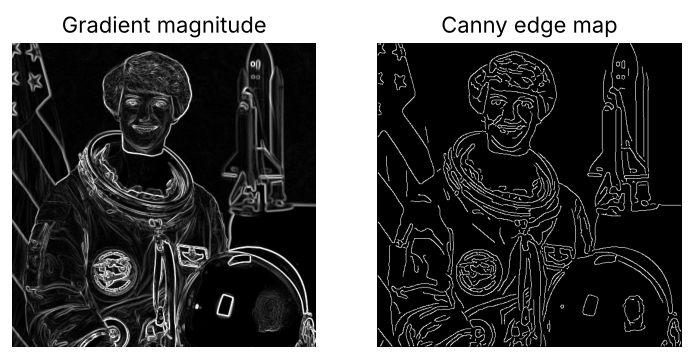

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.8))
axes[0].imshow(magnitude, cmap='gray', vmin=0, vmax=np.percentile(magnitude, 99))
axes[0].set_title('Gradient magnitude')
axes[1].imshow(edges, cmap='gray')
axes[1].set_title('Canny edge map')
for ax in axes:
    ax.axis('off')
plt.show()

## Laplacian

The **Laplacian** adds the second differences along both axes,

$$\nabla^2 I = \frac{\partial^2 I}{\partial x^2} + \frac{\partial^2 I}{\partial y^2}.$$

The 1D second difference is [1, -2, 1]. Adding it along rows and along columns gives the kernel below.

In [60]:
laplacian = np.array([
    [0, 1, 0],
    [1, -4, 1],
    [0, 1, 0],
])

A linear ramp has constant slope and zero curvature. Sobel responds to it, but the Laplacian does not.

In [61]:
ramp = np.array([
    [10, 20, 30],
    [10, 20, 30],
    [10, 20, 30],
])

print('Sobel x:  ', np.sum(ramp * sobel_x))
print('Laplacian:', np.sum(ramp * laplacian))

Sobel x:   80
Laplacian: 0


Second differences strongly amplify pixel-to-pixel noise. Smoothing first suppresses the noise, so larger structures such as the eyes remain visible.

In [62]:
lap_noisy = correlate(noisy, laplacian)
lap_smooth = correlate(gaussian_filter(noisy, 2), laplacian)

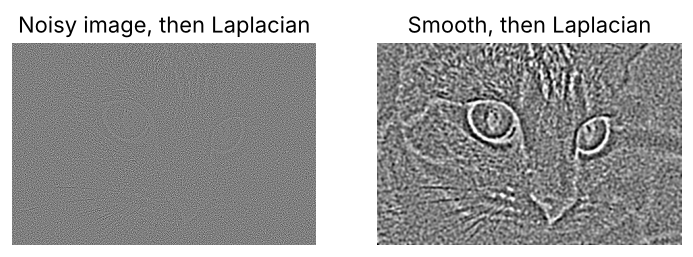

In [63]:
show_signed(
    [lap_noisy, lap_smooth],
    ['Noisy image, then Laplacian', 'Smooth, then Laplacian'],
)

## Other Kernels

Changing the weights changes what the kernel detects. **Prewitt** smooths with [1, 1, 1], **Scharr** smooths with [3, 10, 3], and the **emboss** kernel compares opposite corners.

In [64]:
prewitt_x = np.outer([1, 1, 1], [-1, 0, 1])
scharr_x = np.outer([3, 10, 3], [-1, 0, 1])
emboss = np.array([
    [-2, -1, 0],
    [-1, 0, 1],
    [0, 1, 2],
])

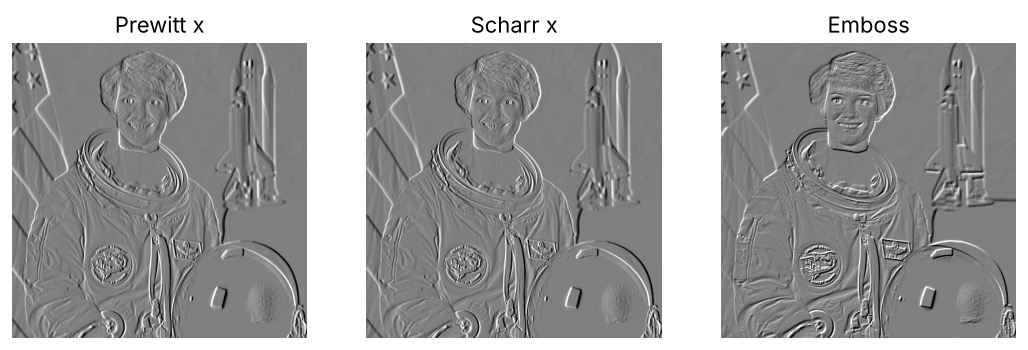

In [65]:
show_signed(
    [correlate(gray, prewitt_x), correlate(gray, scharr_x), correlate(gray, emboss)],
    ['Prewitt x', 'Scharr x', 'Emboss'],
)